# Visualizing fire scars through false color

Author: Gitanjali Sharma

GirHub: https://github.com/gitanjali1024/eds220-hwk4.git

## About

In this notebook we create true and false color maps to visualize fire scars from the Eaton and Palisades fires.

### Highlights
- Data wrangling and exploration with `pandas`
- Geospatial wrangling with `geopandas` 
- Data wrangling and exploration with `xarray` and `rioxarray`
- Creating  and customizing true and false color imagery maps

### About the Data

This notebook uses two datasets:

1) Landsat 8 reflectance bands
The first is a simplified collection of bands (red, green, blue, near-infrared and shortwave infrared) from the Landsat Collection 2 Level-2 atmospherically corrected surface reflectance data, collected by the Landsat 8 satellite.The data was retrieved from the Microsoft Planetary Computer data catalog and clipped to an area surrounding the fire perimeters. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2


2) Fire perimeters for Eaton and Palisades fires
The second dataset will be fire perimeters for the Eaton and Palisades fires. This data is from the CAL FIRE Historical fire perimeter dataset, and is housed on the LA county ArcGIS hub. It was downlaoded as a shapefile, with one file for each fire. https://egis-lacounty.hub.arcgis.com/datasets/lacounty::palisades-and-eaton-dissolved-fire-perimeters-2025

### References

Los Angeles County. (2025). Palisades and Eaton dissolved fire perimeters (2025) [GIS dataset]. Los Angeles County Enterprise GIS. https://egis-lacounty.hub.arcgis.com/datasets/lacounty::palisades-and-eaton-dissolved-fire-perimeters-2025

Microsoft. (n.d.). Landsat Collection 2 Level-2. Microsoft Planetary Computer. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2

### Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import os
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt


### Import data

In [ ]:
# Eaton fire boundary
fp_eaton = os.path.join('data', 'Eaton_Perimeter_20250121', 'Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(fp_eaton)

# Palisades fire boundary
fp_palisades = os.path.join('data', 'Palisades_Perimieter_20250121', 'Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(fp_palisades)

### Fire Perimeter Data Exploration

In [4]:
# Look at the head of Eaton GeoDataFrame
eaton.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


In [5]:
# Find CRS of Eaton GeoDataFrame
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [6]:
# Look at head of Palisades GeoDataFrame
palisades.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


In [7]:
# Find CRS of Palisades GeoDataFrame
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

Each dataset contains information on the fire perimeter for a single fire -- either the Eaton fire or the Palisades fire. The CRS is EPSG:4269 which is a geographic CRS, meaning it has not been projected onto a flat plane, and will need to be reprojected before mapping.

### NetCDF data import and exploration

In [8]:
# Load in Landsat data
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

In [ ]:
# Display landsat data
landsat


<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

This dataset has two dimensions -- x and y. X indicates the x coordinate of projection and y indicates the y coordinate of projection. These are also two of its coordinates, however it has a third coordinate time.  x and y have a unit of meters and a resolution of 30 meters, while time is just a single coordinate of when the data was captured (February 23, 2025). The variables are the different bands: red, green, blue, near infrared, and shortwave.

### Restoring geospatial information

In [ ]:
# a. Use `rio.crs` to print the CRS of this dataset. Is this a geospatial object?
print(landsat.rio.crs)

None


Using rio.crs on this dataset returns a value of "none". This indicates that landsat is not recognized as geospatial object because the there is not CRS information attached to the xarray, and therefore it cannot be mapped.

In [24]:

# b. You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable `spatial_ref`.

# Print the CRS using `spatial_ref.crs_wkt` attribute 
print(landsat.spatial_ref.crs_wkt)


PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [25]:

# c. Recover the geospatial information by using `rio.write_crs()` and the spatial reference information from part b.

# Save the WKT CRS into landsat data
landsat = landsat.rio.write_crs(landsat.spatial_ref.crs_wkt)

# Print CRS
print(landsat.rio.crs)

EPSG:32611


### True color image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


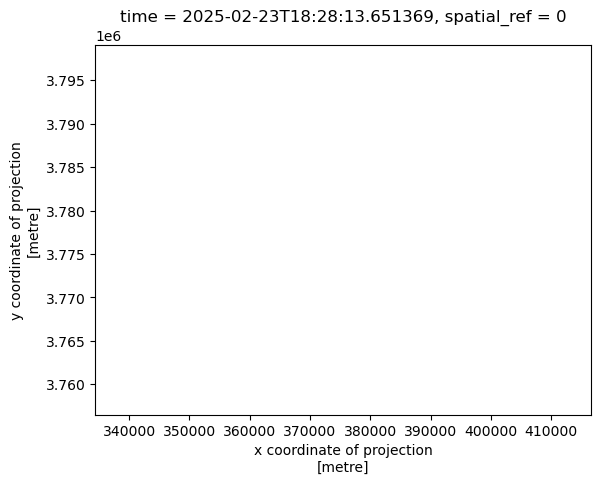

In [ ]:

# a. Without creating any new variables:
# Select the red, green, and blue variables (in that order) of the `xarray.Dataset` holding the Landsat data
# Convert it to an `xarray.DataArray` using the `to_dataarray()` method, and then
# Use `.plot.imshow()` to create an RGB image with the data. There will be a warning; that’s ok.

# Select data and plot
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

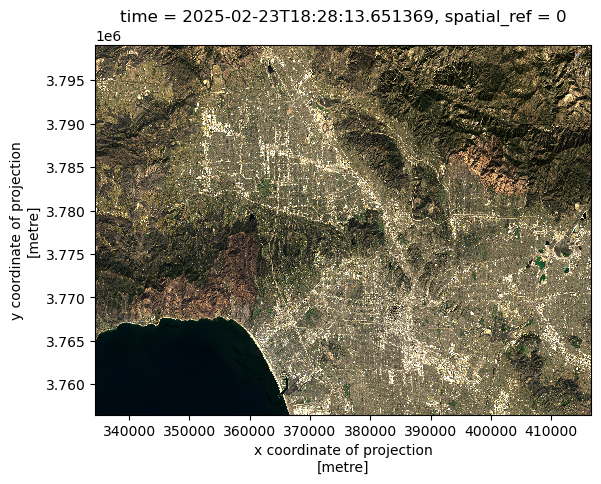

In [37]:

# b. Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.

# Plot true color image by using robust=True (scale colors and ignore extreme outliers)

# Create plot
landsat[['red','green','blue']].to_dataarray().plot.imshow(robust=True)

In [32]:

# c. To resolve the other warning, identify which bands have `nan` values. 
# HINT: There are many ways of doing so. One option is to use `numpy.isnan()`.
print(np.isnan(landsat).sum())

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0


In [34]:
# d. Use the `.fillna()` method for `xarray.Datasets` to replace any nan values in the Landsat data with zero.

# Replace NA values with 0
landsat = landsat.fillna(value = 0)

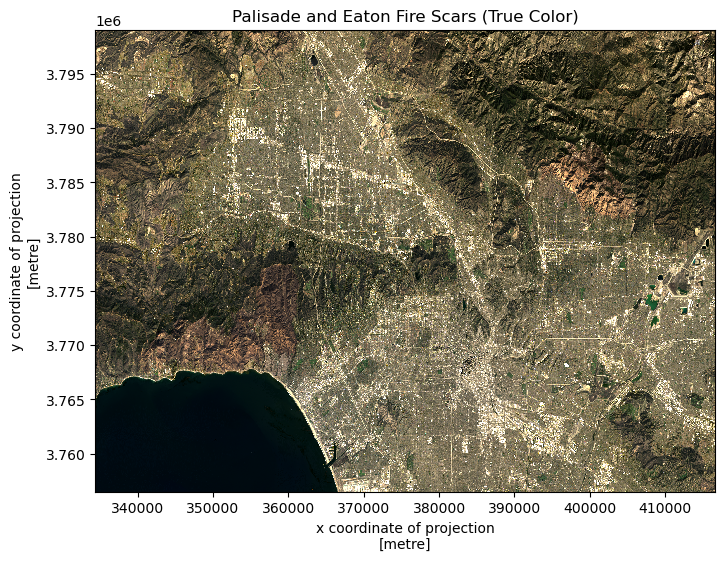

In [39]:
# e. Create a new true color image that gets plotted without warnings.

# Plot image
fig, ax = plt.subplots(figsize=(8,6))

landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(ax=ax, robust=True)

plt.title('Palisade and Eaton Fire Scars (True Color)')

# Display plot
plt.show()

Part a has no visible map and looks completely white because the landsat values are above 1, which is generally the maximum value for imshow -- every pixel taking on the maximum value makes the entire image white. Using robust=True scales all of the values, putting them between 0 and 1 and excluding very extreme values, allowing us to see the image much more clearly. Removing the N/A values also removes a warning, and the final image is a True color imagery representation with no warnings. 

### False color image

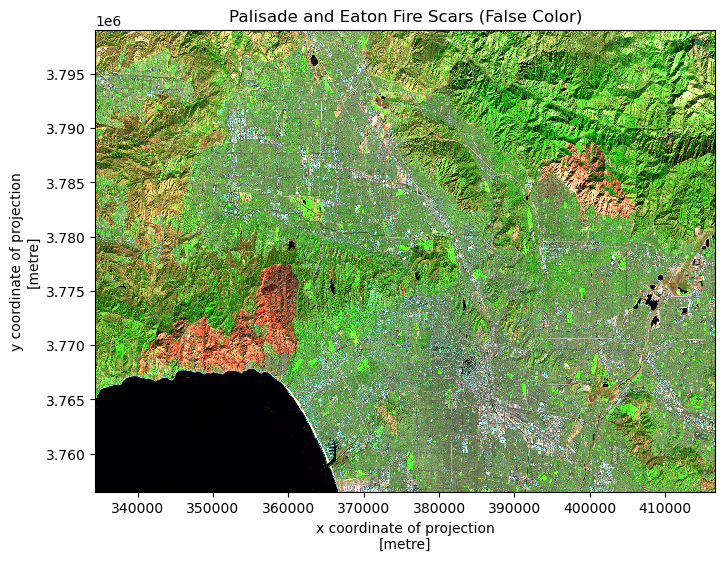

In [ ]:
# Plot image

fig, ax = plt.subplots(figsize=(8,6))

landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(ax=ax, robust=True)

plt.title('Palisade and Eaton Fire Scars (False Color)')

plt.show()

### Map

In [41]:
# Check if CRS matches
landsat.rio.crs == eaton.crs

False

In [43]:
# Change CRS to match
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

# Confirm match
print(landsat.rio.crs == eaton.crs)
print(landsat.rio.crs == palisades.crs)

True
True


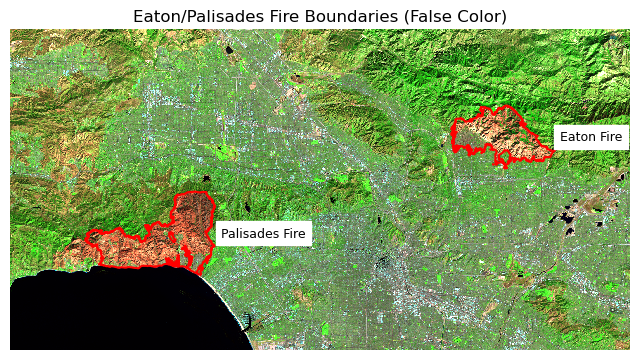

In [49]:

# Plot data
fig, ax = plt.subplots(figsize=(8, 6))
ax.axis('off')

landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(
    ax=ax,
    robust=True
)

eaton.boundary.plot(ax=ax, color='red')
palisades.boundary.plot(ax=ax, color='red')

# Add a label to the right of each fire
for fire, label in [(eaton, "Eaton Fire"), (palisades, "Palisades Fire")]:
    minx, miny, maxx, maxy = fire.total_bounds
    offset = (maxx - minx) * 0.05

    ax.text(
        maxx + offset,         
        (miny + maxy) / 2,     
        label,
        fontsize=9,
        color='black',
        ha='left',
        va='center',
        backgroundcolor='white'
    )

ax.set_title('Eaton/Palisades Fire Boundaries (False Color)')

plt.show()
     


This map uses false color imagery to represent the areas burned by the 2025 Eaton and Palisades fire. In this false color map, the red band is assigned to the blue channel, the shortwave infrared band is assigned to the red channel, and the near infared band is assigned to the red channel. Under this kind of false color imagery, healthy vegetation appears bright green, while burned or dead vegetation appears more red. We can clearly see that the burned areas from these fires, as shown from the fire perimeter, appear to have significantly less healthy vegetation comapred to the surrounding areas.